**Predicción multiclase de riesgo cardiovascular**

**Objetivo:** clasificar a los pacientes en tres niveles de riesgo cardiovascular a partir de 27 variables sociodemográficas, clínicas, analíticas y de estilo de vida.

| Clase | Significado |
|---|---|
| 0 | Bajo riesgo |
| 1 | Riesgo moderado |
| 2 | Alto riesgo |

**Dataset:** `data/enfermedad_cardiovascular.csv` (2.254 pacientes, 27 variables de entrada + 1 objetivo).

> Este notebook unifica dos análisis exploratorios del grupo: el de Rodrigo (calidad de los datos, distribuciones y correlaciones) y el EDA clínico de Pablo (`eda_clinico.ipynb`: variables categóricas y binarias frente al riesgo y estudio de la imputación).

# Librerías
Importar las librerías necesarias y fijar la semilla para garantizar la reproducibilidad.

In [53]:
import pandas as pd
import seaborn as sns
import numpy as np
from matplotlib import pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.experimental import enable_iterative_imputer  # habilita IterativeImputer (sigue siendo experimental)
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer

import utils.constantes as cte   # semilla común del proyecto, definida en un solo sitio

%matplotlib inline

np.random.seed(cte.semilla)

# 1. EDA

Objetivo de esta fase: auditar la calidad del dataset e identificar todas las problemáticas presentes en las variables (apartado 3.1 del enunciado).

## 1.1. Carga de datos

Cargar el CSV en un DataFrame.

In [54]:
url = ('../data/enfermedad_cardiovascular.csv')
datos = pd.read_csv(url, sep=',')
datos.head(3)

,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,...,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo,riesgo_cardiovascular
0,57.4,192.0,78.9,371.24,62.6,149.1,245.6,NaN,30.4,95.1,...,5.41,1,1,1,0,1,Mediterránea,Moderadamente activo,Ninguno,2
1,51.7,131.2,80.0,270.20,35.4,NaN,173.8,137.5,29.7,85.3,...,6.11,0,1,0,1,1,Baja en carbohidratos,Ligeramente activo,Ambos,1
2,56.7,127.1,92.5,202.30,47.7,134.1,60.9,157.4,29.4,87.5,...,6.52,1,1,0,0,1,Baja en carbohidratos,Sedentario,Ninguno,2


## 1.2. Descripción del dataset

Ver las dimensiones, tipos de datos, valores estadísticos y valores duplicados.

In [55]:
datos.info()
display(datos.describe(include='all').T)
display(datos.shape)
datos.duplicated().sum()
datos.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 2254 entries, 0 to 2253
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   edad                          2254 non-null   float64
 1   presion_sistolica             2254 non-null   float64
 2   presion_diastolica            2254 non-null   float64
 3   colesterol_total              2254 non-null   float64
 4   colesterol_hdl                2254 non-null   float64
 5   colesterol_ldl                2119 non-null   float64
 6   trigliceridos                 2254 non-null   float64
 7   glucosa_ayunas                2142 non-null   float64
 8   indice_masa_corporal          2254 non-null   float64
 9   frecuencia_cardiaca_reposo    2254 non-null   float64
 10  horas_sueno_diarias           2074 non-null   float64
 11  consumo_alcohol_semanal       2254 non-null   float64
 12  anos_fumador                  2254 non-null   float64
 13  proteina_c_rea

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
edad,2254.0,NaN,NaN,NaN,56.688287,14.448018,9.8,47.2,56.9,66.475,103.5
presion_sistolica,2254.0,NaN,NaN,NaN,132.315186,26.931005,52.2,115.3,129.65,143.9,231.36
presion_diastolica,2254.0,NaN,NaN,NaN,82.167524,13.084058,30.8,73.6,82.1,91.1,122.5
colesterol_total,2254.0,NaN,NaN,NaN,228.133829,62.725948,61.1,188.2,221.2,252.5,448.59
colesterol_hdl,2254.0,NaN,NaN,NaN,47.2252,15.991614,-8.8,36.7,47.3,58.2,106.3
colesterol_ldl,2119.0,NaN,NaN,NaN,135.638603,36.732756,6.1,111.4,135.5,161.4,266.7
trigliceridos,2254.0,NaN,NaN,NaN,176.657391,72.735893,-35.7,133.05,170.0,208.1,452.7
glucosa_ayunas,2142.0,NaN,NaN,NaN,104.10733,24.939696,32.0,86.3,103.75,120.475,194.0
indice_masa_corporal,2254.0,NaN,NaN,NaN,28.09339,6.470585,3.6,23.8,28.0,32.5,50.6
frecuencia_cardiaca_reposo,2254.0,NaN,NaN,NaN,73.66819,12.762546,25.8,65.0,73.1,82.3,112.7


(2254, 28)

edad                              0
presion_sistolica                 0
presion_diastolica                0
colesterol_total                  0
colesterol_hdl                    0
colesterol_ldl                  135
trigliceridos                     0
glucosa_ayunas                  112
indice_masa_corporal              0
frecuencia_cardiaca_reposo        0
horas_sueno_diarias             180
consumo_alcohol_semanal           0
anos_fumador                      0
proteina_c_reactiva             157
acido_urico                       0
clearance_creatinina              0
frecuencia_ejercicio_semanal      0
perimetro_cintura                 0
hemoglobina_glicosilada           0
fumador_actual                    0
hipertension_previa               0
diabetes_mellitus                 0
tratamiento_estatinas             0
uso_antihipertensivos             0
tipo_alimentacion                 0
nivel_actividad                   0
antecedentes_familiares_tipo      0
riesgo_cardiovascular       

**Estructura general**
- Filas y columnas: 2254 filas y 28 columnas
- Duplicados: 0 registros duplicados
- Valores nulos: Columnas `colesterol_ldl` = 135, `glucosa_ayunas` = 112, `horas_sueno_diarias` = 180, y `proteina_c_reactiva` = 157.

**Anómalos**
- Mínimos anómalos: Registros negativos en `colesterol_hdl`, `trigliceridos` y `consumo_alcohol_semanal`, `indice_masa_corporal` = 3.6 incompatible con la vida humana 3.6 (un índice menor a 10 u 11 se consideraría severamente crítico), `edad` = 9.8 no es adulto.
- Máximos anómalos: `frecuencia_ejercicio_semanal` mayor a 7 días de la semana,

**Posibles outliers**
- Valores a comprobar clínicamente: `presion_sistolica` = 231.36, `presion_diastolica` = 122.5, `colesterol_total` = 448.59, `trigliceridos` = 452.7, `proteinca_c_reactiva` = 12.88, `acido_urico` = 12.29, `horas_sueno_diarias` = 1.6.

## 1.3. Tipos de variables

Separar las variables según su tipo, porque cada grupo se analiza y se preprocesa de forma distinta. Estas listas se usan en todo el notebook.

In [56]:
objetivo = "riesgo_cardiovascular"
binarias = ["fumador_actual", "hipertension_previa", "diabetes_mellitus",
            "tratamiento_estatinas", "uso_antihipertensivos"]
categoricas = ["tipo_alimentacion", "nivel_actividad", "antecedentes_familiares_tipo"]
numericas = [c for c in datos.columns if c not in binarias + categoricas + [objetivo]]   # las 19 numéricas

## 1.4. Variable objetivo

Ver cuántos pacientes hay en cada clase de riesgo y en qué porcentaje, para comprobar si el dataset está desbalanceado.

riesgo_cardiovascular
0    1127
1     676
2     451
Name: count, dtype: int64

riesgo_cardiovascular
0    0.500000
1    0.299911
2    0.200089
Name: proportion, dtype: float64

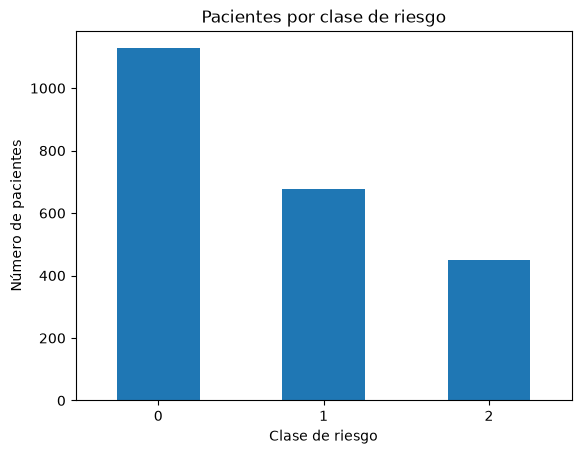

In [57]:
count_classes = datos['riesgo_cardiovascular'].value_counts(sort=True)
display(count_classes)
count_classes.plot(kind = 'bar', rot=0)

display(datos['riesgo_cardiovascular'].value_counts(normalize=True))


plt.title("Pacientes por clase de riesgo")
plt.xlabel("Clase de riesgo")
plt.ylabel("Número de pacientes");

El dataset está desbalanceado: la clase 0 (bajo riesgo) tiene 1127 pacientes (50 %), la clase 1 (riesgo moderado) 676 (30 %) y la clase 2 (alto riesgo) 451 (20 %), siendo el alto riesgo la clase minoritaria.

**Qué error importa más**

Tenemos las siguientes categorías que están ordenadas (bajo < moderado < alto):

* 0 = Bajo riesgo
* 1 = Riesgo moderado
* 2 = Alto riesgo

Esto nos indica que estamos ante un problema de clasificación con 3 clases. Como es un caso clínico en el que clasificamos a un paciente según su riesgo cardiovascular, el error más grave es clasificar a un paciente de riesgo alto como de riesgo bajo: se iría a casa sin seguimiento. Ese error debe ser el que más se castigue, seguido de clasificar a un paciente de riesgo alto como de riesgo moderado. Por eso la sensibilidad (recall) de la clase de riesgo alto va a ser una de las métricas más importantes:

$$
\text{Sensibilidad}=\frac{VP}{VP+FN}=\frac{VP}{P}
$$

El desbalance es moderado. Esto implica que:

1. Un modelo que siempre clasificase como "riesgo bajo", ya nos daría un 50% de accuracy, lo cual es engañoso y por eso es importante el recall de la clase de riesgo alto.
2. Las particiones de train, test y validación cruzada deben ser estratificadas para mantener la proporción 50/30/20.

## 1.5. Distribuciones

Visualizar distribución de los datos

### 1.5.1. Variables numéricas

<Axes: >

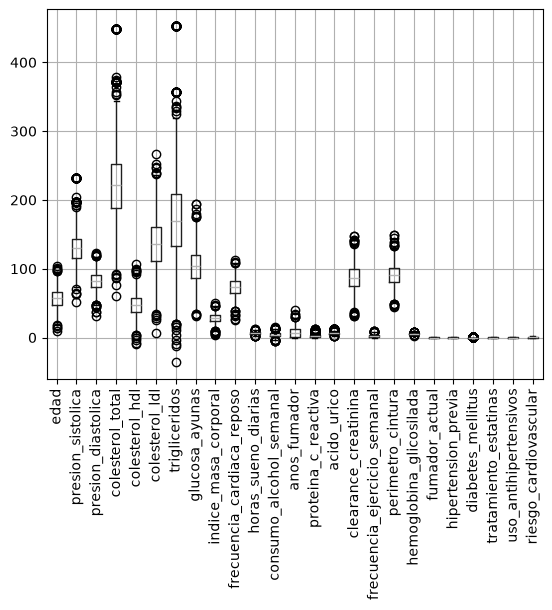

In [58]:
datos.boxplot(rot=90)

/tmp/ipykernel_1829/213701758.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=datos, x=objetivo, y=variable, palette="Dark2")
/tmp/ipykernel_1829/213701758.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=datos, x=objetivo, y=variable, palette="Dark2")
/tmp/ipykernel_1829/213701758.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=datos, x=objetivo, y=variable, palette="Dark2")
/tmp/ipykernel_1829/213701758.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. A

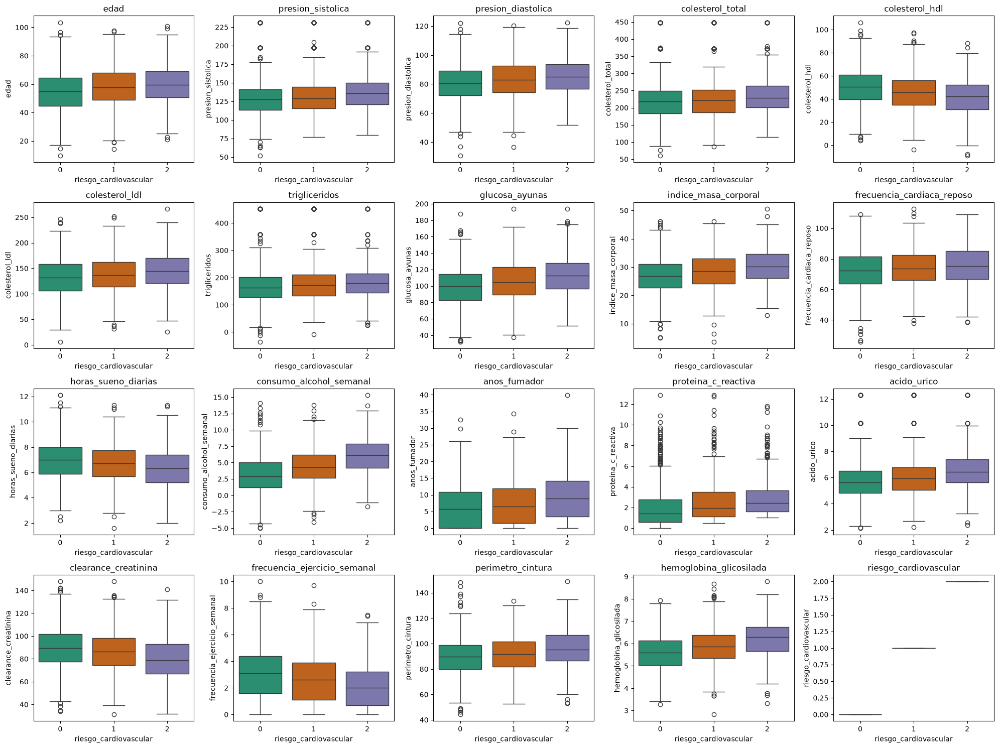

In [59]:
# el objetivo se añade a las numéricas para poder colorear por clase
variables_continuas = numericas + [objetivo]

plt.figure(figsize=(20, 15))

for i, variable in enumerate(variables_continuas):
    plt.subplot(4, 5, i+1)
    sns.boxplot(data=datos, x=objetivo, y=variable, palette="Dark2")
    plt.title(variable)

plt.tight_layout()
plt.show()

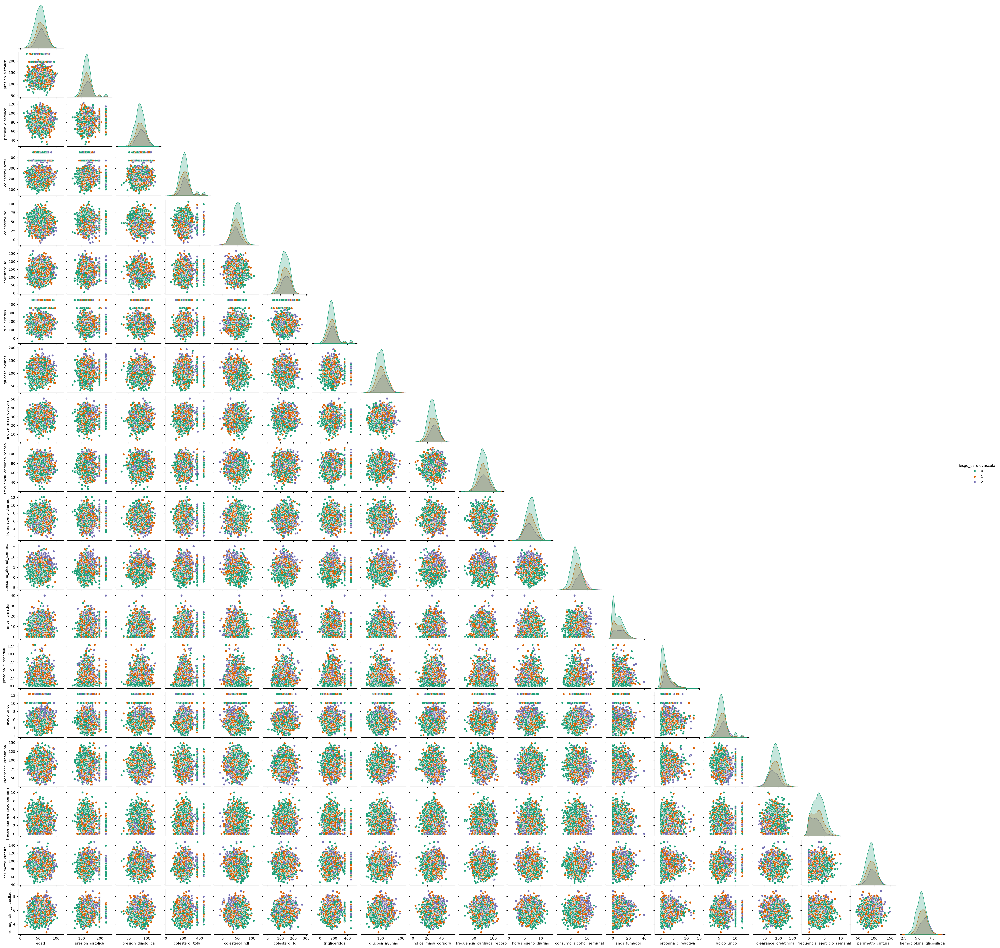

In [60]:
# Visualizar scatter en conjunto a distribuciones

sns.pairplot(datos[variables_continuas], hue="riesgo_cardiovascular", height=2, palette='Dark2', corner=True)

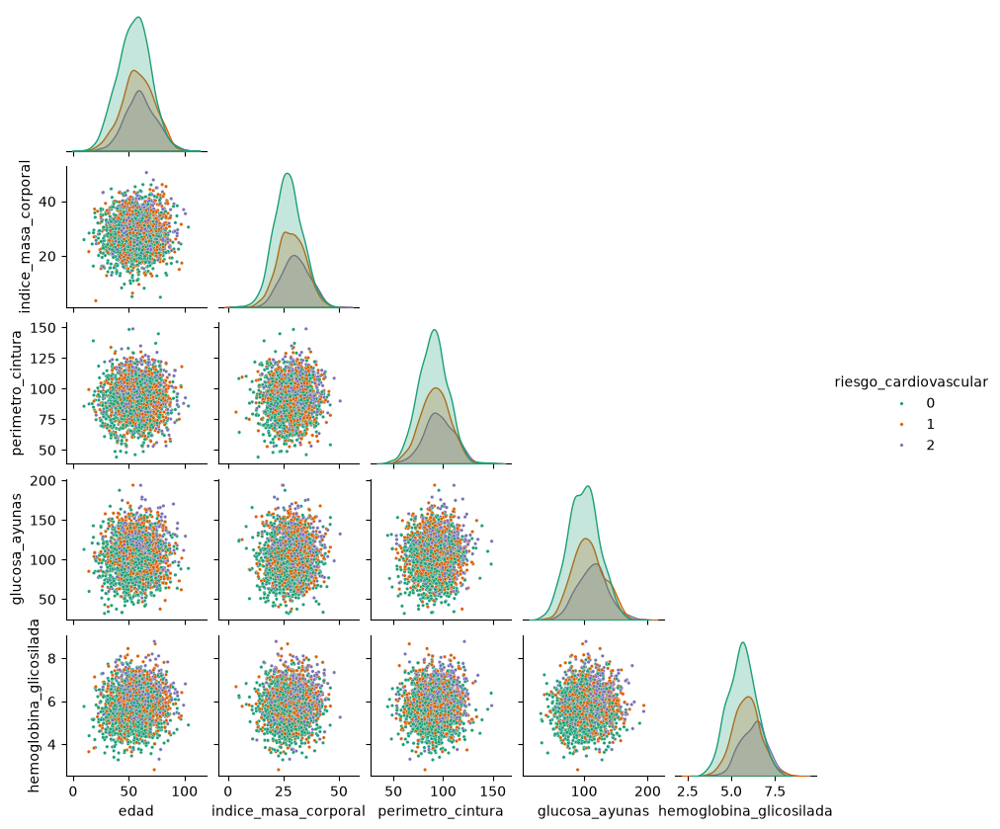

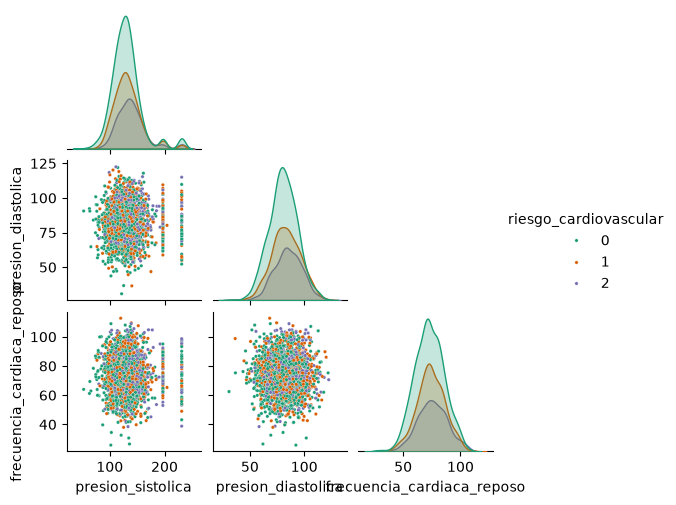

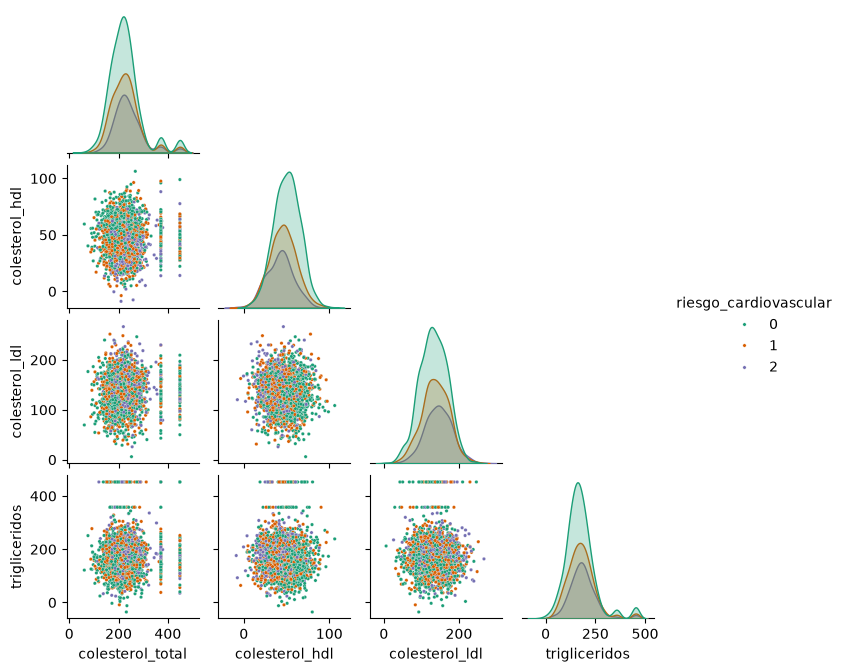

In [61]:
# Desagregar por tipo de perfil de acuerdo con variables relacionadas

# Perfil Físico y Metabólico
perfil_fisico = ["edad", "indice_masa_corporal", "perimetro_cintura", "glucosa_ayunas", "hemoglobina_glicosilada", "riesgo_cardiovascular"]
sns.pairplot(datos[perfil_fisico], hue="riesgo_cardiovascular", palette='Dark2', corner=True, height=1.7, plot_kws={'s': 6})

# Perfil Cardiovascular puro
perfil_cardio = ["presion_sistolica", "presion_diastolica", "frecuencia_cardiaca_reposo", "riesgo_cardiovascular"]
sns.pairplot(datos[perfil_cardio], hue="riesgo_cardiovascular", palette='Dark2', corner=True, height=1.7, plot_kws={'s': 6})

# Perfil de Lípidos
perfil_lipidos = ["colesterol_total", "colesterol_hdl", "colesterol_ldl", "trigliceridos", "riesgo_cardiovascular"]
sns.pairplot(datos[perfil_lipidos], hue="riesgo_cardiovascular", palette='Dark2',corner=True, height=1.7, plot_kws={'s': 6})

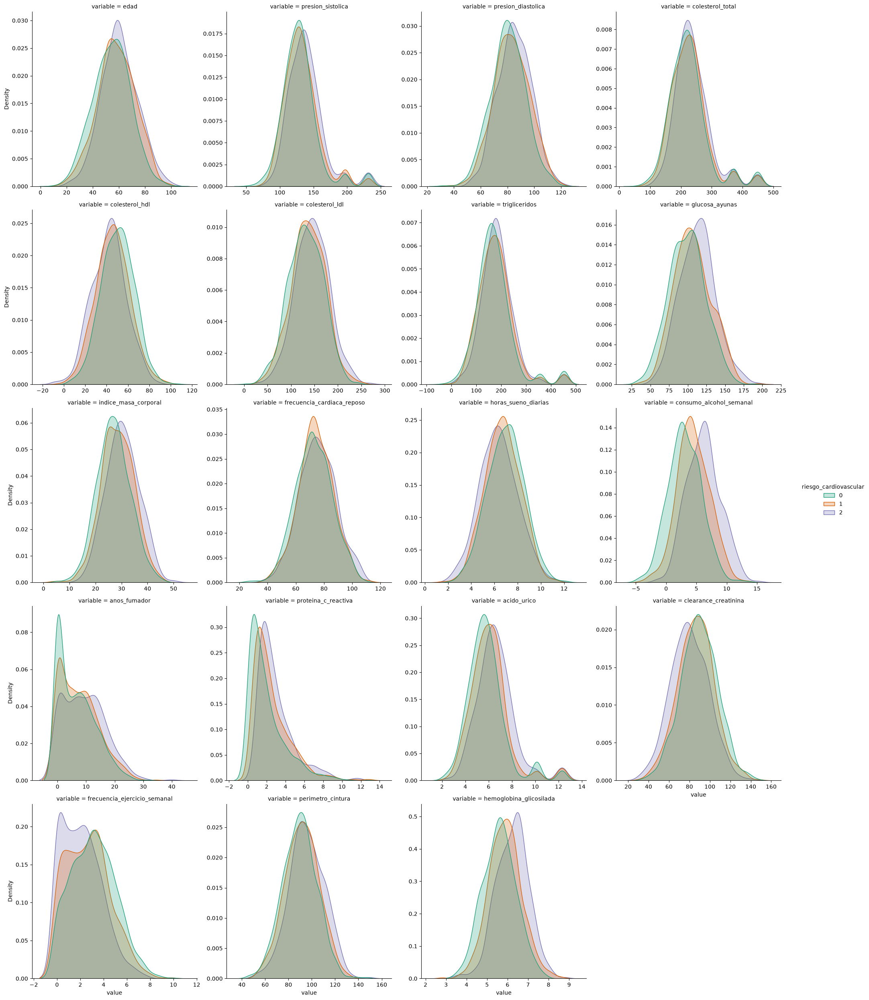

In [62]:
# Visualizar solo distribuciones de clases

datos_continuos = datos[variables_continuas].melt(id_vars='riesgo_cardiovascular')
sns.displot(
    data=datos_continuos, x="value", hue="riesgo_cardiovascular", col="variable", 
    kind="kde", common_norm=False, fill=True, col_wrap=4, palette="Dark2",
    facet_kws={'sharex': False, 'sharey': False}
)

Mediana de cada variable numérica por clase de riesgo. Se usa la mediana para que no la condicionen los valores extremos ni los nulos.

In [63]:
print("Mediana de cada variable numérica por clase de riesgo:")
display(datos.groupby(objetivo)[numericas].median().T)

Mediana de cada variable numérica por clase de riesgo:


riesgo_cardiovascular,0,1,2
edad,54.90,57.800,59.60
presion_sistolica,127.70,129.100,135.60
presion_diastolica,80.30,82.950,85.00
colesterol_total,218.00,221.100,229.00
colesterol_hdl,50.60,45.650,42.20
colesterol_ldl,131.80,137.000,144.80
trigliceridos,163.80,171.500,180.20
glucosa_ayunas,99.60,104.600,112.60
indice_masa_corporal,26.80,28.500,30.20
frecuencia_cardiaca_reposo,72.30,73.700,75.30


**Conclusión.** Las medianas de las variables cambian de forma ordenada de riesgo bajo a alto: todas las numéricas aportan algo.

### 1.5.2. Variables binarias

**Hipótesis:** fumar, tener hipertensión o diabetes y estar en tratamiento deberían ir con más riesgo.

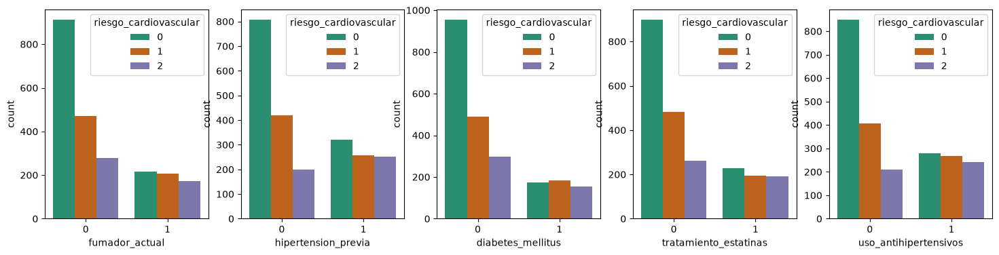

In [64]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for i, col in enumerate(binarias):
    sns.countplot(data=datos, x=col, hue=objetivo, ax=axes[i], palette="Dark2")

plt.show()

In [65]:
# Al ser una variable binaria, que el valor sea 1 significa que el paciente tiene la condición,
#  por lo que a mayor valor medio, mayor riesgo. 
datos.groupby(objetivo)[binarias].mean().T.round(2)

riesgo_cardiovascular,0,1,2
fumador_actual,0.19,0.30,0.39
hipertension_previa,0.28,0.38,0.56
diabetes_mellitus,0.15,0.27,0.34
tratamiento_estatinas,0.20,0.29,0.42
uso_antihipertensivos,0.25,0.40,0.53


La hipótesis se cumple, de hecho, el 56 % de los pacientes de riesgo alto tiene hipertensión previa y el 53 % toma antihipertensivos.

Al ser variables binarias, estas no necesitan ser codificadas.

### 1.5.3. Variables categóricas

**Hipótesis (conocimiento clínico):**

* `tipo_alimentacion`: se suele decir que la dieta mediterránea es la más saludable, así que espero menos riesgo cardiovascular en esos pacientes.
* `nivel_actividad`: más actividad física, menos riesgo; el sedentarismo, más riesgo.
* `antecedentes_familiares_tipo`: los antecedentes familiares probablemente expliquen un mayor riesgo cardiovascular.

/tmp/ipykernel_1829/481328204.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=datos, x=variable, palette="Dark2")
/tmp/ipykernel_1829/481328204.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=datos, x=variable, palette="Dark2")
/tmp/ipykernel_1829/481328204.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=datos, x=variable, palette="Dark2")


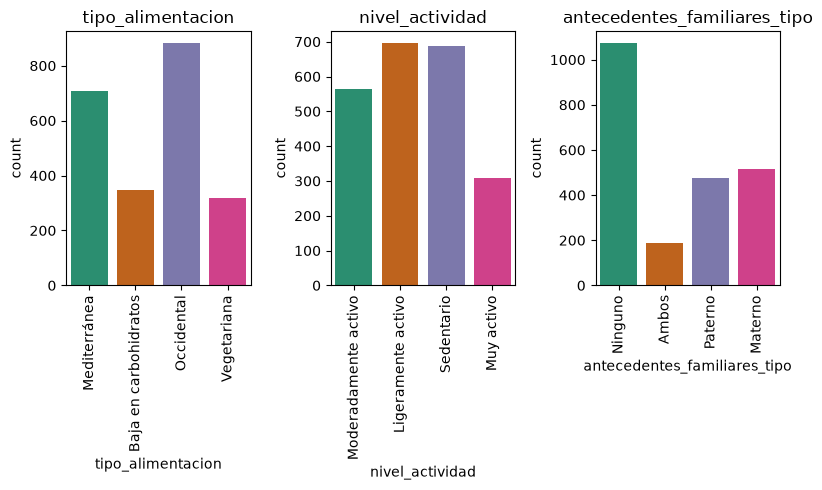

In [66]:
plt.figure(figsize=(8, 5))

for i, variable in enumerate(categoricas):
    plt.subplot(1, 3, i+1)
    sns.countplot(data=datos, x=variable, palette="Dark2")
    plt.title(variable)
    plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

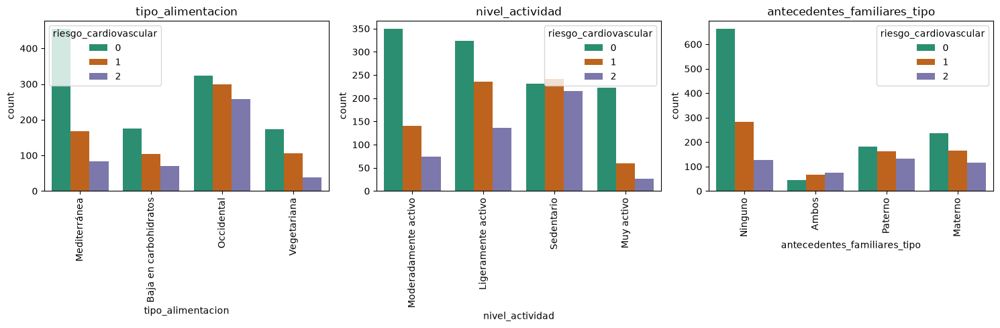

In [67]:
# Gráfico de variables str desagregado por clases de riesgo cardiovascular

plt.figure(figsize=(15, 5))

for i, variable in enumerate(categoricas):
    plt.subplot(1, 3, i+1)
    sns.countplot(data=datos, x=variable, hue=objetivo, palette="Dark2")
    plt.title(variable)
    plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

Porcentaje de pacientes de cada clase de riesgo dentro de cada categoría:

In [68]:
orden = {
    "tipo_alimentacion": ["Mediterránea", "Vegetariana", "Baja en carbohidratos", "Occidental"],
    "nivel_actividad": ["Sedentario", "Ligeramente activo", "Moderadamente activo", "Muy activo"],
    "antecedentes_familiares_tipo": ["Ninguno", "Materno", "Paterno", "Ambos"],
}

for cat in categoricas:
    tabla = pd.crosstab(datos[cat], datos[objetivo], normalize="index").reindex(orden[cat]).round(2)
    tabla["pacientes"] = datos[cat].value_counts()
    display(tabla)

riesgo_cardiovascular,0,1,2,pacientes
tipo_alimentacion,,,,
Mediterránea,0.64,0.24,0.12,706
Vegetariana,0.54,0.33,0.12,318
Baja en carbohidratos,0.50,0.30,0.20,349
Occidental,0.37,0.34,0.29,881


riesgo_cardiovascular,0,1,2,pacientes
nivel_actividad,,,,
Sedentario,0.34,0.35,0.31,687
Ligeramente activo,0.47,0.34,0.20,695
Moderadamente activo,0.62,0.25,0.13,563
Muy activo,0.72,0.19,0.08,309


riesgo_cardiovascular,0,1,2,pacientes
antecedentes_familiares_tipo,,,,
Ninguno,0.62,0.26,0.12,1072
Materno,0.46,0.32,0.22,517
Paterno,0.38,0.34,0.28,477
Ambos,0.24,0.36,0.40,188


**Conclusión.** Las tres hipótesis se cumplen:

* **Alimentación:** Tiene riesgo alto el 12 % de los pacientes con dieta mediterránea o vegetariana, frente al 29 % de los que siguen la occidental.

* **Actividad:** el riesgo alto baja de forma **ordenada**, del 31 % (sedentario) al 8 % (muy activo).

* **Antecedentes:** ninguno 12 %, materno 22 %, paterno 28 % y ambos 40 %.

**Implicación para el preprocesamiento:**

| Variable | Propuesta | Por qué |
|---|---|---|
| `tipo_alimentacion` | One-hot | Categorías sin orden |
| `nivel_actividad` | Ordinal (0 a 3, con el orden de arriba) | El riesgo sigue ese orden; con one-hot se perdería |
| `antecedentes_familiares_tipo` | Dos binarias: `antecedente_materno` y `antecedente_paterno` («Ambos» = 1 y 1) | Refleja lo que significa la variable y su efecto casi aditivo |

**Observaciones**
- En variables continuas las clases parecen solaparse y no ser linealmente separables. Se identifican además para las variables `presion_sistolica`, `colesterol_total`, `trigliceridos`, `acido_urico` valores de instancias constantes fuera de la nube de puntos del scatterplot que se deben analizar a profundidad.
- En varaibles binarias se evidencia que la clase mayoritaria es riesgo = 0 (bajo riesgo)
- En las variables de texto solo aparecen las 4 categorías del diccionario del enunciado, sin erratas (1.7)

## 1.6. Valores faltantes

Ver el porcentaje de datos nulos y ver como se distribuyen entre clases de riesgo y pacientes.

In [69]:
# porcentaje de nulos por columna
display(datos.isnull().mean().mul(100))

# porcentaje de nulos por clase de riesgo
display(datos.isnull().groupby(datos['riesgo_cardiovascular']).mean().mul(100))

# nulos por paciente
display(datos.isnull().sum(axis=1).value_counts())
print(f"Pacientes con al menos un nulo: {datos.isna().any(axis=1).sum()} ({datos.isna().any(axis=1).mean():.0%})")

edad                            0.000000
presion_sistolica               0.000000
presion_diastolica              0.000000
colesterol_total                0.000000
colesterol_hdl                  0.000000
colesterol_ldl                  5.989352
trigliceridos                   0.000000
glucosa_ayunas                  4.968944
indice_masa_corporal            0.000000
frecuencia_cardiaca_reposo      0.000000
horas_sueno_diarias             7.985803
consumo_alcohol_semanal         0.000000
anos_fumador                    0.000000
proteina_c_reactiva             6.965395
acido_urico                     0.000000
clearance_creatinina            0.000000
frecuencia_ejercicio_semanal    0.000000
perimetro_cintura               0.000000
hemoglobina_glicosilada         0.000000
fumador_actual                  0.000000
hipertension_previa             0.000000
diabetes_mellitus               0.000000
tratamiento_estatinas           0.000000
uso_antihipertensivos           0.000000
tipo_alimentacio

,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,...,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo,riesgo_cardiovascular
riesgo_cardiovascular,,,,,,,,,,,,,,,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,6.388642,0.0,4.436557,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,6.065089,0.0,4.585799,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,4.878049,0.0,6.873614,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


0    1721
1     484
2      47
3       2
Name: count, dtype: int64

Pacientes con al menos un nulo: 533 (24%)


Hay nulos en 4 variables: `colesterol_ldl` (6 %), `glucosa_ayunas` (5 %), `horas_sueno_diarias` (8 %) y `proteina_c_reactiva` (7 %) y no parece que la aprición de datos nulos dependa del tipo de paciente. Además, al ser escasos, con sustituirlos por un valor razonable, será suficiente.

Los nulos están repartidos entre pacientes distintos: si se eliminaran las filas con algún nulo se perdería **casi uno de cada cuatro pacientes**. Se descarta eliminar filas y se estudia cómo imputar cada variable en la 1.10, después de limpiar los errores de registro.

## 1.7. Calidad de los datos

Comprobar los valores anómalos obtenidos en `describe()` (negativos, valores sin sentido clínico, incoherencias entre variables) y los valores que se repiten de forma sospechosa.

In [70]:
(datos[numericas] < 0).sum()

edad                              0
presion_sistolica                 0
presion_diastolica                0
colesterol_total                  0
colesterol_hdl                    4
colesterol_ldl                    0
trigliceridos                     4
glucosa_ayunas                    0
indice_masa_corporal              0
frecuencia_cardiaca_reposo        0
horas_sueno_diarias               0
consumo_alcohol_semanal         177
anos_fumador                      0
proteina_c_reactiva               0
acido_urico                       0
clearance_creatinina              0
frecuencia_ejercicio_semanal      0
perimetro_cintura                 0
hemoglobina_glicosilada           0
dtype: int64

In [71]:
# valores sin sentido clínico
print('Pacientes menores de 18 años:', (datos['edad'] < 18).sum())
print('Pacientes con IMC menor de 12:', (datos['indice_masa_corporal'] < 12).sum())
print('Pacientes con más de 7 días de ejercicio a la semana:', (datos['frecuencia_ejercicio_semanal'] > 7).sum())

Pacientes menores de 18 años: 4
Pacientes con IMC menor de 12: 13
Pacientes con más de 7 días de ejercicio a la semana: 41


In [72]:
# valores incoherentes
print('Presión sistólica menor o igual que la diastólica:', (datos['presion_sistolica'] <= datos['presion_diastolica']).sum())
print('HDL + LDL mayor que el colesterol total:', ((datos['colesterol_hdl'] + datos['colesterol_ldl']) > datos['colesterol_total']).sum())
print('Años fumando mayores que la edad:', (datos['anos_fumador'] > datos['edad']).sum())

Presión sistólica menor o igual que la diastólica: 44
HDL + LDL mayor que el colesterol total: 559
Años fumando mayores que la edad: 1


In [73]:
# comprobar que las variables corresponden al tipo de datos que deben tener
print('Pacientes con la edad con decimales:', (datos['edad'] % 1 != 0).sum())
print('Pacientes con los días de ejercicio con decimales:', (datos['frecuencia_ejercicio_semanal'] % 1 != 0).sum())

for col in binarias + [objetivo]:
    print(col, datos[col].unique())

for col in categoricas:
    display(datos[col].value_counts(dropna=False))

Pacientes con la edad con decimales: 2046
Pacientes con los días de ejercicio con decimales: 1836
fumador_actual [1 0]
hipertension_previa [1 0]
diabetes_mellitus [1 0]
tratamiento_estatinas [0 1]
uso_antihipertensivos [1 0]
riesgo_cardiovascular [2 1 0]


tipo_alimentacion
Occidental               881
Mediterránea             706
Baja en carbohidratos    349
Vegetariana              318
Name: count, dtype: int64

nivel_actividad
Ligeramente activo      695
Sedentario              687
Moderadamente activo    563
Muy activo              309
Name: count, dtype: int64

antecedentes_familiares_tipo
Ninguno    1072
Materno     517
Paterno     477
Ambos       188
Name: count, dtype: int64

In [74]:
# valores que se repiten
for col in ['presion_sistolica', 'colesterol_total', 'trigliceridos', 'acido_urico']:
    print(col)
    display(datos[col].value_counts().head(3))

presion_sistolica


presion_sistolica
196.95    59
231.36    53
133.70    10
Name: count, dtype: int64

colesterol_total


colesterol_total
371.24    74
448.59    61
242.20     8
Name: count, dtype: int64

trigliceridos


trigliceridos
452.70    54
357.56    36
177.60     6
Name: count, dtype: int64

acido_urico


acido_urico
10.13    61
12.29    51
5.83     16
Name: count, dtype: int64

**Valores imposibles o sin sentido clínico**
- Hay valores negativos en `consumo_alcohol_semanal` (177), `colesterol_hdl` (4) y `trigliceridos` (4).
- También se ve que 4 pacientes son menores de 18 años, 13 tienen un IMC menor de 12 y 41 hacen más de 7 días de ejercicio a la semana.

**Incoherencias entre variables**
- 44 pacientes tienen una presión sistólica menor o igual a la diastólica, que es siempre mayor y hay un paciente que lleva más años fumando que la edad que tiene.
- En 559 pacientes (alrededor del 25 %), la suma HDL y LDL es mayor que el colesterol total.
- `edad` (años cumplidos) y `frecuencia_ejercicio_semanal` (días a la semana) deberían ser variables enteras, pero en casi todos los pacientes, tienen decimales (2046 y 1836 de 2254).

**Valores repetidos**
- En `presion_sistolica` (196.95 y 231.36), `colesterol_total` (371.24 y 448.59), `trigliceridos` (452.7 y 357.56) y `acido_urico` (10.13 y 12.29) hay dos valores que se repiten entre 36 y 74 veces, mientras que el siguiente valor más frecuente se repite como mucho 16 veces. Al ser valores decimales, es improbable que haya ocurrido de forma natural y podrían ser valores sustituidos (antiguos nulos).

## 1.8. Correlaciones y redundancia

Ver si hay variables que se relacionan mucho entre sí (posibles variables redundantes) y cuáles se relacionan más con el riesgo cardiovascular.

Se usa la correlación de Spearman en lugar de la de Pearson porque varias variables son asimétricas y tienen valores extremos, y porque el objetivo (0, 1, 2) es ordinal. Las variables binarias se incluyen; las de texto no, porque no tienen orden.

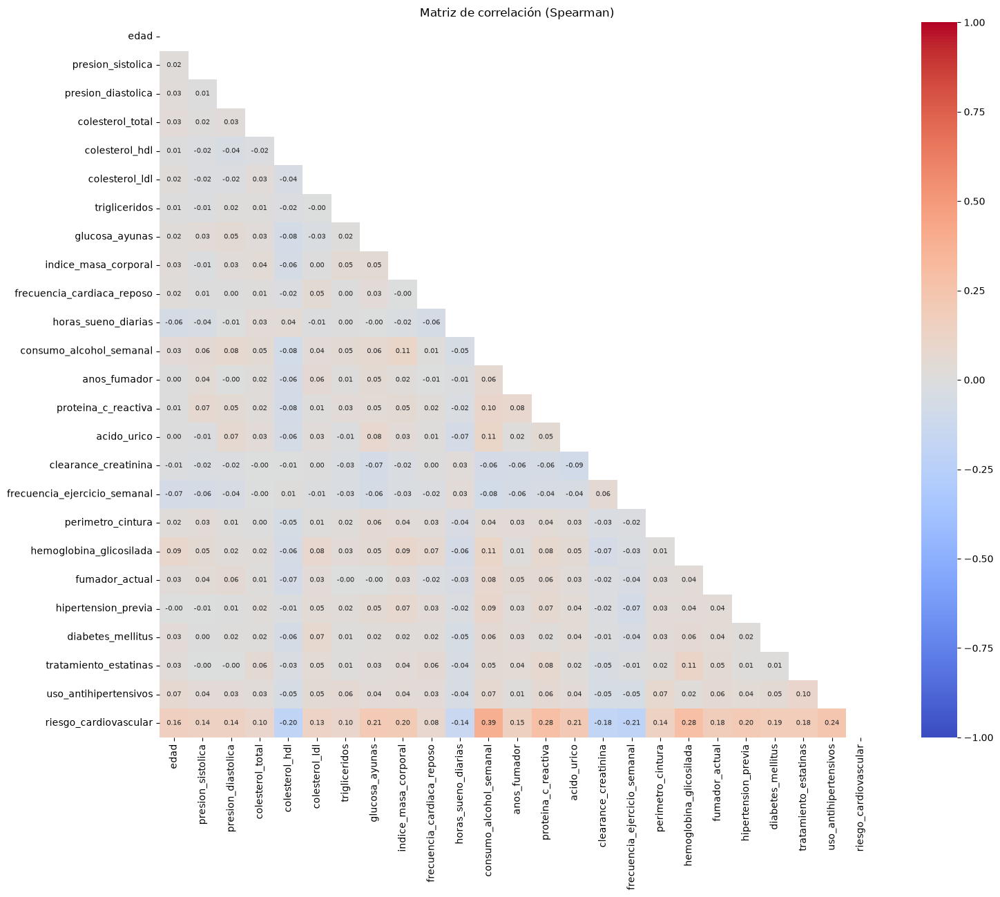

In [75]:
# correlación de Spearman entre las variables numéricas (incluye las binarias y el objetivo)
correlaciones = datos.corr(method='spearman', numeric_only=True)

# máscara para ocultar el triángulo superior, que repite el inferior
mascara = np.triu(np.ones_like(correlaciones, dtype=bool))

plt.figure(figsize=(16, 13))
sns.heatmap(correlaciones, mask=mascara, cmap='coolwarm', vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', annot_kws={'size': 7}, square=True)
plt.title('Matriz de correlación (Spearman)')
plt.tight_layout()
plt.show()

In [76]:
# correlación de cada variable con el riesgo, ordenada por valor absoluto (se mantiene el signo)
# se añade Pearson para comparar: si las dos difieren mucho, hay valores extremos o relaciones no lineales
correlacion_objetivo = pd.DataFrame({
    'spearman': correlaciones['riesgo_cardiovascular'],
    'pearson': datos.corr(numeric_only=True)['riesgo_cardiovascular'],
}).drop('riesgo_cardiovascular')

correlacion_objetivo.sort_values('spearman', key=abs, ascending=False)

,spearman,pearson
consumo_alcohol_semanal,0.387706,0.396681
hemoglobina_glicosilada,0.282734,0.288278
proteina_c_reactiva,0.282499,0.197321
uso_antihipertensivos,0.235951,0.237138
acido_urico,0.212523,0.173992
glucosa_ayunas,0.209647,0.218211
frecuencia_ejercicio_semanal,-0.206637,-0.209816
hipertension_previa,0.204500,0.210978
colesterol_hdl,-0.200020,-0.202634
indice_masa_corporal,0.195778,0.201964


In [77]:
# correlación de parejas de variables que clínicamente deberían estar relacionadas
print('Presión sistólica y diastólica:', datos['presion_sistolica'].corr(datos['presion_diastolica'], method='spearman'))
print('Glucosa en ayunas y hemoglobina glicosilada:', datos['glucosa_ayunas'].corr(datos['hemoglobina_glicosilada'], method='spearman'))
print('IMC y perímetro de cintura:', datos['indice_masa_corporal'].corr(datos['perimetro_cintura'], method='spearman'))
print('Colesterol total y colesterol LDL:', datos['colesterol_total'].corr(datos['colesterol_ldl'], method='spearman'))

Presión sistólica y diastólica: 0.006917107748012283
Glucosa en ayunas y hemoglobina glicosilada: 0.051088958631578626
IMC y perímetro de cintura: 0.038267905698816336
Colesterol total y colesterol LDL: 0.025837935879883738


In [78]:
# pares de variables de entrada más correlacionados entre sí (posible redundancia)
entradas = correlaciones.drop(index='riesgo_cardiovascular', columns='riesgo_cardiovascular')
inferior = np.tril(np.ones_like(entradas, dtype=bool), k=-1)   # triángulo inferior, sin la diagonal
pares = entradas.where(inferior).stack().dropna()              # en pandas 3, stack() no quita los NaN

print('Pares con correlación mayor que 0.7 en valor absoluto:', (pares.abs() > 0.7).sum())
pares.sort_values(key=abs, ascending=False).head()

Pares con correlación mayor que 0.7 en valor absoluto: 0


tratamiento_estatinas    hemoglobina_glicosilada    0.111345
hemoglobina_glicosilada  consumo_alcohol_semanal    0.109305
consumo_alcohol_semanal  indice_masa_corporal       0.109184
acido_urico              consumo_alcohol_semanal    0.108531
proteina_c_reactiva      consumo_alcohol_semanal    0.098291
dtype: float64

**Redundancia**
- Ningún par de variables de entrada supera una correlación de 0,7 (el más fuerte es 0,11), así que no hay variables redundantes que haya que quitar.
- Variables que clínicamente deberían estar relacionadas salen casi independientes: presión sistólica y diastólica (0,01), glucosa y hemoglobina glicosilada (0,05), IMC y perímetro de cintura (0,04) y colesterol total y LDL (0,03). Esto indica que las variables se generaron de forma independiente, lo que encaja con la incoherencia HDL + LDL > colesterol total de la 1.7.

**Relación con el riesgo**
- Las variables más relacionadas con el riesgo son el consumo de alcohol (0,39), la hemoglobina glicosilada (0,28) y la proteína C reactiva (0,28). El ejercicio, el HDL, el aclaramiento de creatinina y las horas de sueño se relacionan de forma negativa (a más, menos riesgo), lo que tiene sentido clínico. Aun así, correlación no implica causalidad.
- Todas las relaciones son débiles o moderadas: el riesgo depende de la combinación de muchas variables y no de una sola.
- La variable más relacionada, el consumo de alcohol, es la que tiene 177 valores negativos, así que su tratamiento en el preprocesamiento es especialmente importante.

**Pearson frente a Spearman**
- Dan valores casi iguales, salvo en las variables más asimétricas y con valores repetidos extremos, como la proteína C reactiva (0,20 con Pearson y 0,28 con Spearman). Los valores extremos distorsionan Pearson, lo que justifica usar Spearman.

**Advertencia**
- Este análisis es descriptivo. Una correlación baja no implica que una variable no sirva, porque solo mide relaciones monótonas; y si se usara para eliminar variables, la decisión tendría que tomarse solo con los datos de entrenamiento.

## 1.9. Limpieza de errores de registro

Aplicar las reglas de la 1.7 a una copia de los datos (`datos_limpios`). Los apartados anteriores describen el dataset tal como llega; a partir de aquí se trabaja con la copia limpia.

Son reglas fijas del dominio de cada variable, no estadísticos que se aprendan de los datos, así que se pueden aplicar antes de separar train y test. La excepción parcial son los valores repetidos: se detectaron mirando el dataset completo, aunque la regla resultante (dos valores concretos por variable) es fija.

| Problema (1.7) | Regla |
|---|---|
| Menores de 18 años | Eliminar al paciente: no pertenece a la población del estudio |
| HDL o triglicéridos negativos, IMC menor de 12 | Pasar a nulo |
| Presión sistólica menor o igual que la diastólica | Pasar a nulo las dos presiones, porque no se sabe cuál es la errónea |
| Consumo de alcohol negativo | Recortar a 0, para conservar que el paciente bebe poco |
| Más de 7 días de ejercicio a la semana | Recortar a 7, para conservar que el paciente hace mucho ejercicio |
| Valores repetidos sospechosos | Pasar a nulo: son nulos camuflados |

Los nulos que se crean aquí se imputan después dentro del `Pipeline`, igual que los originales.

In [79]:
# copia para no modificar los datos originales, que se siguen usando en los apartados anteriores
datos_limpios = datos.copy()

# 1) menores de 18 años: se eliminan, porque la cohorte es de adultos
datos_limpios = datos_limpios[datos_limpios['edad'] >= 18].reset_index(drop=True)

# 2) valores imposibles: se pasan a nulo
datos_limpios.loc[datos_limpios['colesterol_hdl'] < 0, 'colesterol_hdl'] = np.nan
datos_limpios.loc[datos_limpios['trigliceridos'] < 0, 'trigliceridos'] = np.nan
datos_limpios.loc[datos_limpios['indice_masa_corporal'] < 12, 'indice_masa_corporal'] = np.nan

# presión sistólica <= diastólica: no se sabe cuál de las dos está mal, así que se anulan ambas
presion_incoherente = datos_limpios['presion_sistolica'] <= datos_limpios['presion_diastolica']
datos_limpios.loc[presion_incoherente, ['presion_sistolica', 'presion_diastolica']] = np.nan

# 3) recortes que conservan la información del paciente
datos_limpios['consumo_alcohol_semanal'] = datos_limpios['consumo_alcohol_semanal'].clip(lower=0)
datos_limpios['frecuencia_ejercicio_semanal'] = datos_limpios['frecuencia_ejercicio_semanal'].clip(upper=7)

# 4) nulos camuflados: los dos valores que más se repiten en cada variable (vistos en la 1.7)
for col in ['presion_sistolica', 'colesterol_total', 'trigliceridos', 'acido_urico']:
    camuflados = datos[col].value_counts().head(2)
    print(col, camuflados.to_dict())
    datos_limpios.loc[datos_limpios[col].isin(camuflados.index), col] = np.nan

presion_sistolica {196.95: 59, 231.36: 53}
colesterol_total {371.24: 74, 448.59: 61}
trigliceridos {452.7: 54, 357.56: 36}
acido_urico {10.13: 61, 12.29: 51}


In [80]:
# comparar los nulos antes y después de la limpieza
nulos_limpieza = pd.DataFrame({
    'nulos antes': datos[numericas].isna().sum(),
    'nulos después': datos_limpios[numericas].isna().sum(),
})
nulos_limpieza['% después'] = (nulos_limpieza['nulos después'] / len(datos_limpios) * 100).round(1)
display(nulos_limpieza[nulos_limpieza['nulos después'] > 0])

print(f"Pacientes: {len(datos)} antes y {len(datos_limpios)} después")
print(f"Pacientes con al menos un nulo: {datos_limpios[numericas].isna().any(axis=1).sum()} "
      f"({datos_limpios[numericas].isna().any(axis=1).mean():.0%})")

,nulos antes,nulos después,% después
presion_sistolica,0,156,6.9
presion_diastolica,0,44,2.0
colesterol_total,0,135,6.0
colesterol_hdl,0,4,0.2
colesterol_ldl,135,134,6.0
trigliceridos,0,94,4.2
glucosa_ayunas,112,112,5.0
indice_masa_corporal,0,13,0.6
horas_sueno_diarias,180,180,8.0
proteina_c_reactiva,157,157,7.0


Pacientes: 2254 antes y 2250 después
Pacientes con al menos un nulo: 884 (39%)


**Conclusión.**

- Los valores repetidos son los mismos que se vieron en la 1.7: dos por variable, que aparecen entre 36 y 74 veces.
- Se eliminan los 4 menores de 18 años, así que quedan 2.250 pacientes.
- Ahora hay nulos en 11 variables, en vez de 4. Los nuevos vienen de los nulos camuflados (`presion_sistolica`, `colesterol_total`, `trigliceridos` y `acido_urico`), de las 44 presiones incoherentes (que suman nulos en la sistólica y en la diastólica) y de unos pocos valores imposibles en `colesterol_hdl` (4) e `indice_masa_corporal` (13). Ninguna variable supera el 8 % de nulos.
- El 39 % de los pacientes tiene al menos un nulo, frente al 24 % de antes de la limpieza. Eliminar esas filas haría perder 884 pacientes, así que hay que imputar.

## 1.10. Tratamiento de los valores faltantes

Decidir cómo imputar cada variable con nulos, ya con los datos limpios: los nulos originales y los que ha creado la limpieza.

### 1.10.1. ¿Se puede calcular el LDL que falta?

La fórmula de Friedewald nos permite calcular de forma aproximada el LDL:

$$
\text{LDL} \approx \text{Colesterol total} - \text{HDL} - \frac{\text{Triglicéridos}}{5}
$$
Vamos a comprobar si es una aproximación correcta para rellenar estos valores nulos:

In [81]:
# 1) Comprobamos el error medio en los pacientes medidos si rellenamos los nulos con la fórmula de Friedewald,
#  y 2) si rellenamos con la mediana de LDL.
ldl_calculado = datos_limpios["colesterol_total"] - datos_limpios["colesterol_hdl"] - datos_limpios["trigliceridos"] / 5
conocido = datos_limpios["colesterol_ldl"].notna() & ldl_calculado.notna()
ldl_real = datos_limpios.loc[conocido, "colesterol_ldl"]
print(f"Error medio con Friedewald: {(ldl_real - ldl_calculado[conocido]).abs().mean():.1f} mg/dL")
print(f"Error medio rellenando con la mediana: {(ldl_real - ldl_real.median()).abs().mean():.1f} mg/dL")

Error medio con Friedewald: 47.4 mg/dL
Error medio rellenando con la mediana: 29.5 mg/dL


In [82]:
# 2) Condiciones de validez de la fórmula y coherencia física (HDL + LDL no puede superar al CT)
print("TG >= 400 (Friedewald no aplica):", (datos_limpios["trigliceridos"] >= 400).sum())
print("LDL calculado negativo:", (ldl_calculado < 0).sum())
print("HDL + LDL > colesterol total:", (datos_limpios["colesterol_hdl"] + datos_limpios["colesterol_ldl"] > datos_limpios["colesterol_total"]).sum())

TG >= 400 (Friedewald no aplica): 0
LDL calculado negativo: 5
HDL + LDL > colesterol total: 558


**Conclusión.**

- Con los datos sin limpiar parecía que la fórmula no se podía aplicar a 54 pacientes con triglicéridos ≥ 400 mg/dL. Esos 54 eran justo el valor camuflado 452,7: una vez limpios los datos, ningún paciente llega a 400.
- Aun así, Friedewald se equivoca más que rellenar con la mediana (47,4 frente a 29,5 mg/dL de error medio), da 5 LDL negativos y HDL + LDL supera al colesterol total en 558 pacientes. Las tres variables no son coherentes entre sí (1.8), así que no se puede calcular una a partir de las otras.
- Se descarta Friedewald. Si se pudiera consultar al equipo médico, convendría preguntar cómo se tomaron estos datos y si se pueden recuperar los que faltan.

### 1.10.2. Diagnóstico de cada variable con nulos

Para cada variable con nulos, una función reutilizable comprueba si que falte el dato se relaciona con el riesgo, si alguna otra variable la acompaña y si es simétrica:

In [83]:
def diagnostico_nulos(df, variable, objetivo, predictoras,
                      umbral_corr=0.3,  alfa=0.05):
    """Resume las tres comprobaciones que deciden cómo imputar `variable`.

    1. Si que falte el dato se relaciona con el riesgo (chi²) -> ¿añadir un indicador de nulo?
    2. Si alguna otra variable la acompaña (Spearman)          -> ¿imputación multivariante?
    3. Si es simétrica o tiene cola (asimetría)                -> ¿media o mediana?
    """
    nulo = df[variable].isna()              # True en los pacientes a los que les falta el dato
    clase_alta = df[objetivo].max()         # la clase de riesgo alto (2)

    # 1) Tabla "falta el dato (sí/no)" × clase de riesgo. Si el p-valor es bajo, la ausencia es informativa.
    tabla = pd.crosstab(nulo, df[objetivo])
    p_riesgo = chi2_contingency(tabla).pvalue
    reparto = pd.crosstab(nulo, df[objetivo], normalize="index")   # % de cada clase en cada grupo

    # 2) Spearman con el resto de predictoras (sin el objetivo: el imputador del Pipeline no ve la y).
    otras = [c for c in predictoras if c != variable]
    rho = df[otras].corrwith(df[variable], method="spearman")
    mejor = rho.abs().idxmax()              # la que más se relaciona, sea con signo + o −

    # 3) Asimetría con los valores observados: ≈ 0 simétrica, > 0 cola a la derecha, < 0 a la izquierda
    asimetria = df[variable].skew()

    # Decisión: primero miro si hay en qué apoyarse para una imputación multivariante; si no, media o mediana
    if abs(rho[mejor]) >= umbral_corr:
        metodo = "probar multivariante (KNN / Iterative)"
    else:
        metodo = "mediana"   # simétrica: media ≈ mediana; con cola: la mediana es más robusta

    return {
        "variable": variable,
        "% nulos": round(nulo.mean() * 100, 1),
        "% riesgo alto (nulos)": round(reparto.loc[True, clase_alta] * 100, 1),
        "% riesgo alto (con dato)": round(reparto.loc[False, clase_alta] * 100, 1),
        "p chi² riesgo": round(p_riesgo, 3),
        "indicador de nulo": "sí" if p_riesgo < alfa else "no",
        "más correlacionada": mejor,
        "rho": round(rho[mejor], 3),
        "asimetría": round(asimetria, 2),
        "media": round(df[variable].mean(), 2),
        "mediana": round(df[variable].median(), 2),
        "imputación propuesta": metodo,
    }

In [84]:
con_nulos = [c for c in numericas if datos_limpios[c].isna().any()]
resumen = pd.DataFrame([diagnostico_nulos(datos_limpios, v, objetivo, numericas + binarias) for v in con_nulos])
resumen.set_index("variable").T

variable,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,horas_sueno_diarias,proteina_c_reactiva,acido_urico
% nulos,6.9,2.0,6.0,0.2,6.0,4.2,5.0,0.6,8.0,7.0,4.9
% riesgo alto (nulos),18.6,9.1,19.3,75.0,16.4,14.9,27.7,0.0,19.4,16.6,18.9
% riesgo alto (con dato),20.2,20.3,20.1,19.9,20.3,20.3,19.6,20.2,20.1,20.3,20.1
p chi² riesgo,0.787,0.107,0.707,0.018,0.545,0.211,0.116,0.094,0.891,0.08,0.537
indicador de nulo,no,no,no,sí,no,no,no,no,no,no,no
más correlacionada,proteina_c_reactiva,acido_urico,consumo_alcohol_semanal,consumo_alcohol_semanal,hemoglobina_glicosilada,uso_antihipertensivos,acido_urico,consumo_alcohol_semanal,hemoglobina_glicosilada,consumo_alcohol_semanal,consumo_alcohol_semanal
rho,0.063,0.091,0.075,-0.079,0.077,0.061,0.095,0.108,-0.066,0.1,0.115
asimetría,0.14,-0.07,-0.04,0.04,-0.05,0.0,0.12,0.14,0.02,1.59,-0.0
media,128.96,81.83,216.77,47.32,135.66,167.04,104.13,28.21,6.75,2.35,5.79
mediana,128.9,81.8,217.9,47.3,135.5,167.3,103.75,28.1,6.8,1.79,5.81


Matices de la función `diagnostico_nulos`:

1. **El umbral de correlación (0,3) es arbitrario**, pero la decisión no depende de su valor exacto: en las 11 variables, la correlación más alta es de 0,12 (`acido_urico` con `consumo_alcohol_semanal`).
2. **La correlación por parejas no prueba que un imputador multivariante vaya a fallar**, porque KNN combina todas las variables a la vez. Es un indicio, que se comprueba en la 1.10.3.
3. **Usar la media en unas variables y la mediana en otras obligaría a meter dos imputadores** sin ganar nada, porque en las variables simétricas media y mediana casi coinciden. Por eso se propone la mediana para todas.

**Conclusión.**

- Ninguna variable con nulos se relaciona con el resto (la correlación más alta es de 0,12), así que previsiblemente KNN o Iterative no mejorarán a la mediana.
- En 10 de las 11 variables, que falte el dato no se relaciona con el riesgo (p > 0,05). La excepción aparente es `colesterol_hdl` (p = 0,018, porque 3 de sus 4 nulos son de riesgo alto), pero son solo 4 pacientes. Con tan pocos casos el chi-cuadrado no es fiable, porque necesita al menos 5 casos esperados en cada celda. Además, esos nulos no faltaban en el registro: los ha creado la limpieza al anular HDL negativos. Por eso no se añade un indicador de nulo.
- Media y mediana casi coinciden, salvo en `proteina_c_reactiva` (asimetría 1,59; media 2,35 y mediana 1,79). Ahí es más adecuada la mediana.

### 1.10.3. Experimento: comparar imputadores

Para no quedarse en un «previsiblemente», se usa la técnica vista en clase: **esconder valores conocidos, rellenarlos con cada método y medir el error**.

* Se usan los 1.366 pacientes sin ningún nulo después de la limpieza, así se conoce el valor real de cada hueco.
* En cada variable se esconde al azar el mismo porcentaje de valores que le falta de verdad. Esconderlos al azar es coherente con la 1.10.2: que falte el dato no se relaciona con el riesgo.
* Los imputadores ven solo las 19 numéricas, nunca el objetivo, igual que dentro del pipeline.
* Se estandariza antes de imputar, porque KNN mide distancias y, sin escalar, las dominarían el colesterol y los triglicéridos. A la media y la mediana no les afecta.
* El sorteo se repite 30 veces con la semilla del proyecto, porque un solo sorteo puede engañar.
* Se comparan dos métodos univariantes (media y mediana) con tres multivariantes (KNN con 5 y con 25 vecinos, e Iterative), con el MAE y el RMSE.

Los imputadores se ajustan con todos los pacientes completos porque aquí se mide la calidad de la reconstrucción, no un modelo. En el pipeline, el imputador se ajustará solo con los datos de entrenamiento.

In [85]:
predictoras = numericas                                     # solo las 19 numéricas (sin binarias ni objetivo)
completos = datos_limpios[predictoras].dropna().reset_index(drop=True)  # pacientes sin ningún nulo: conozco el valor real
pct_nulos = datos_limpios[con_nulos].isna().mean()                      # oculto el mismo % que falta de verdad
print(f"Pacientes completos: {len(completos)}")
print("Valores que se ocultan en cada sorteo:", (pct_nulos * len(completos)).round().astype(int).to_dict())

imputadores = {
    "media": SimpleImputer(strategy="mean"),
    "mediana": SimpleImputer(strategy="median"),
    "KNN (k=5)": KNNImputer(n_neighbors=5),
    "KNN (k=25)": KNNImputer(n_neighbors=25),
    "Iterative": IterativeImputer(max_iter=10, random_state=cte.semilla),
}

Pacientes completos: 1366
Valores que se ocultan en cada sorteo: {'presion_sistolica': 95, 'presion_diastolica': 27, 'colesterol_total': 82, 'colesterol_hdl': 2, 'colesterol_ldl': 81, 'trigliceridos': 57, 'glucosa_ayunas': 68, 'indice_masa_corporal': 8, 'horas_sueno_diarias': 109, 'proteina_c_reactiva': 95, 'acido_urico': 67}


In [86]:
def un_sorteo(datos, pct_nulos, imputadores, rng):
    """Oculta valores al azar, los reconstruye con cada imputador y mide el error en los huecos."""
    # 1) Máscara: en cada variable marco al azar el mismo % de pacientes que tiene nulos en el dataset real
    mascara = pd.DataFrame(False, index=datos.index, columns=datos.columns)
    for variable, p in pct_nulos.items():
        filas = rng.choice(len(datos), size=round(p * len(datos)), replace=False)
        mascara.loc[filas, variable] = True
    huecos = datos.mask(mascara)                       # pongo NaN donde la máscara es True

    # 2) Estandarizo para que KNN no mida distancias dominadas por las variables de mayor escala
    #    (colesterol, triglicéridos). A la media y la mediana no les afecta: el cambio de escala se deshace al final.
    centro, escala = huecos.mean(), huecos.std()
    z = (huecos - centro) / escala

    # 3) Reconstruyo con cada imputador y comparo con el valor real solo en las celdas ocultas
    filas_resultado = []
    for nombre, imputador in imputadores.items():
        reconstruido = pd.DataFrame(imputador.fit_transform(z), columns=datos.columns) * escala + centro
        for variable in pct_nulos.index:
            ocultos = mascara[variable]
            error = reconstruido.loc[ocultos, variable] - datos.loc[ocultos, variable]
            filas_resultado.append({"método": nombre, "variable": variable,
                                    "MAE": error.abs().mean(),
                                    "RMSE": np.sqrt((error ** 2).mean())})
    return filas_resultado

In [87]:
n_sorteos = 30
rng = np.random.default_rng(cte.semilla)   # un generador con la semilla del proyecto: 30 sorteos distintos pero reproducibles
resultados = pd.DataFrame([
    {**fila, "sorteo": i}
    for i in range(n_sorteos)
    for fila in un_sorteo(completos, pct_nulos, imputadores, rng)
])

def media_desv(metrica):
    """Tabla variable × método con 'media ± desviación' de la métrica en los 30 sorteos."""
    r = resultados.groupby(["variable", "método"])[metrica].agg(["mean", "std"])
    texto = r["mean"].map("{:.2f}".format) + " ± " + r["std"].map("{:.2f}".format)
    return texto.unstack()[list(imputadores)]

display(media_desv("MAE"))
print("Referencia, desviación típica de cada variable:", completos[con_nulos].std().round(2).to_dict())

método,media,mediana,KNN (k=5),KNN (k=25),Iterative
variable,,,,,
acido_urico,1.02 ± 0.07,1.02 ± 0.07,1.10 ± 0.09,1.03 ± 0.08,1.02 ± 0.07
colesterol_hdl,14.17 ± 6.87,14.14 ± 6.86,14.78 ± 7.65,14.41 ± 6.47,14.12 ± 6.84
colesterol_ldl,28.75 ± 2.32,28.76 ± 2.32,31.51 ± 2.41,29.49 ± 2.24,28.74 ± 2.25
colesterol_total,35.48 ± 3.17,35.49 ± 3.18,38.47 ± 3.22,36.03 ± 3.53,35.49 ± 3.24
glucosa_ayunas,20.63 ± 1.77,20.63 ± 1.77,23.00 ± 1.68,20.84 ± 1.77,20.41 ± 1.81
horas_sueno_diarias,1.25 ± 0.08,1.25 ± 0.08,1.35 ± 0.09,1.26 ± 0.08,1.25 ± 0.08
indice_masa_corporal,5.57 ± 1.46,5.57 ± 1.46,6.04 ± 1.56,5.52 ± 1.42,5.51 ± 1.44
presion_diastolica,10.48 ± 1.72,10.48 ± 1.72,11.59 ± 1.68,10.69 ± 1.68,10.47 ± 1.70
presion_sistolica,15.01 ± 1.18,15.01 ± 1.18,16.47 ± 1.37,15.38 ± 1.19,15.08 ± 1.13


Referencia, desviación típica de cada variable: {'presion_sistolica': 18.74, 'presion_diastolica': 12.89, 'colesterol_total': 43.99, 'colesterol_hdl': 15.89, 'colesterol_ldl': 36.71, 'trigliceridos': 53.94, 'glucosa_ayunas': 25.54, 'indice_masa_corporal': 6.43, 'horas_sueno_diarias': 1.56, 'proteina_c_reactiva': 2.05, 'acido_urico': 1.25}


In [88]:
# Comparación por parejas: en cada sorteo todos los métodos rellenan los mismos huecos,
# así que puedo contar en qué % de sorteos cada método mejora a la mediana.
mae = resultados.pivot_table(index=["variable", "sorteo"], columns="método", values="MAE")
victorias = mae.drop(columns="mediana").lt(mae["mediana"], axis=0).groupby("variable").mean()
display((victorias * 100).round(0)[[m for m in imputadores if m != "mediana"]])

método,media,KNN (k=5),KNN (k=25),Iterative
variable,,,,
acido_urico,53.0,10.0,30.0,50.0
colesterol_hdl,13.0,47.0,43.0,50.0
colesterol_ldl,40.0,0.0,17.0,53.0
colesterol_total,53.0,3.0,23.0,50.0
glucosa_ayunas,47.0,0.0,37.0,77.0
horas_sueno_diarias,13.0,3.0,33.0,43.0
indice_masa_corporal,30.0,37.0,57.0,67.0
presion_diastolica,50.0,10.0,30.0,63.0
presion_sistolica,47.0,7.0,10.0,50.0


In [89]:
display(media_desv("RMSE"))

método,media,mediana,KNN (k=5),KNN (k=25),Iterative
variable,,,,,
acido_urico,1.27 ± 0.09,1.27 ± 0.09,1.36 ± 0.10,1.28 ± 0.09,1.27 ± 0.09
colesterol_hdl,15.58 ± 7.34,15.57 ± 7.33,16.58 ± 8.36,16.12 ± 7.13,15.51 ± 7.27
colesterol_ldl,35.94 ± 2.66,35.94 ± 2.66,39.33 ± 2.81,36.59 ± 2.59,35.87 ± 2.61
colesterol_total,44.19 ± 3.68,44.22 ± 3.66,47.61 ± 3.74,44.52 ± 4.05,44.13 ± 3.81
glucosa_ayunas,25.53 ± 2.20,25.52 ± 2.20,28.17 ± 1.99,25.71 ± 2.24,25.35 ± 2.28
horas_sueno_diarias,1.56 ± 0.09,1.56 ± 0.09,1.69 ± 0.11,1.57 ± 0.09,1.56 ± 0.08
indice_masa_corporal,6.54 ± 1.56,6.55 ± 1.55,7.21 ± 1.55,6.57 ± 1.52,6.51 ± 1.52
presion_diastolica,13.06 ± 1.96,13.07 ± 1.95,14.46 ± 1.86,13.28 ± 1.75,13.05 ± 1.87
presion_sistolica,18.73 ± 1.31,18.72 ± 1.31,20.58 ± 1.57,19.10 ± 1.29,18.65 ± 1.25


**Conclusión.**

* **KNN con 5 vecinos es el peor.** En 9 de las 11 variables mejora a la mediana en el 10 % de los sorteos o menos. Las excepciones son `colesterol_hdl` e `indice_masa_corporal`, donde solo se esconden 2 y 8 valores por sorteo y los resultados son muy ruidosos (el MAE del HDL varía ±6,9 entre sorteos). Con 25 vecinos se acerca a la media: cuantos más vecinos promedia, más se parece a rellenar con el promedio global. Es decir, los vecinos no aportan información.
* **Iterative empata con la media y la mediana.** Su mayor ventaja está en la glucosa: 20,41 frente a 20,63 mg/dL de MAE con la mediana (la mejora en el 77 % de los sorteos). Son 0,2 mg/dL, muy por debajo de la variación entre sorteos (±1,8). No justifica usar un imputador experimental.
* **En `proteina_c_reactiva`, elegir entre media y mediana depende de la métrica.** Con el MAE gana la mediana (1,47 frente a 1,55; la media solo la mejora en el 13 % de los sorteos). Con el RMSE gana la media (2,06 frente a 2,14). Es una propiedad matemática: entre los valores constantes, la mediana es la que minimiza el error absoluto, y la media, el cuadrático. Se elige el MAE porque está en las unidades de la variable y no lo dominan los pocos pacientes con la PCR muy alta.
* **En todos los métodos, el MAE está entre 0,7 y 0,9 veces la desviación típica** (por ejemplo, 15,0 frente a 18,7 mmHg en la presión sistólica). Es lo esperable al rellenar siempre con el centro de la distribución: ningún método recupera el valor del paciente.

Esto confirma la 1.10.2: la **mediana** es igual o mejor que las alternativas, es la más sencilla y no necesita escalado.

### 1.10.4. ¿Cambia la distribución al imputar?

Se nos ha insistido varias veces en clase que, si se imputa, hay que comparar los estadísticos de la distribución antes y después: si cambian, la imputación ha metido ruido.

In [90]:
con_mediana = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(datos_limpios[con_nulos]), columns=con_nulos)
pd.DataFrame({
    "media antes": datos_limpios[con_nulos].mean(),
    "media después": con_mediana.mean(),
    "mediana antes": datos_limpios[con_nulos].median(),
    "mediana después": con_mediana.median(),
    "desv. típica antes": datos_limpios[con_nulos].std(),
    "desv. típica después": con_mediana.std(),
}).round(2)

,media antes,media después,mediana antes,mediana después,desv. típica antes,desv. típica después
presion_sistolica,128.96,128.95,128.90,128.90,18.88,18.21
presion_diastolica,81.83,81.83,81.80,81.80,12.89,12.77
colesterol_total,216.77,216.83,217.90,217.90,44.08,42.73
colesterol_hdl,47.32,47.32,47.30,47.30,15.85,15.84
colesterol_ldl,135.66,135.65,135.50,135.50,36.74,35.63
trigliceridos,167.04,167.05,167.30,167.30,53.95,52.81
glucosa_ayunas,104.13,104.11,103.75,103.75,24.94,24.31
indice_masa_corporal,28.21,28.21,28.10,28.10,6.31,6.30
horas_sueno_diarias,6.75,6.75,6.80,6.80,1.58,1.52
proteina_c_reactiva,2.35,2.31,1.79,1.79,1.97,1.91


**Conclusión.** Al imputar con la mediana, la media y la mediana de cada variable apenas cambian. La desviación típica baja un poco, como mucho un 4 % (horas de sueño: de 1,58 a 1,52), porque los valores imputados se concentran en el centro. El efecto es pequeño porque ninguna variable tiene más de un 8 % de nulos.

**Propuesta para la siguiente fase:** imputar las variables numéricas con `SimpleImputer(strategy="median")` **dentro del pipeline**, para que la mediana se calcule solo con los datos de entrenamiento de cada fold. Los apartados 1.10.1 a 1.10.4 justifican esta elección, así que en la fase de modelado no haría falta volver a comparar imputadores.

## 1.11. Resumen de problemáticas y técnicas de preprocesamiento

Resumir las problemáticas detectadas en el EDA y proponer, para cada una, una técnica de preprocesamiento con su justificación (apartado 3.1 del enunciado: mínimo 3 técnicas justificadas).

| Problemática | Evidencia en el EDA | Técnica propuesta | Justificación |
|---|---|---|---|
| Valores faltantes | 4 variables con entre un 5 % y un 8 % de nulos en origen (1.6). Tras la limpieza, 11 variables con hasta un 8 % y el 39 % de los pacientes con algún nulo (1.9). Que falte el dato no se relaciona con el riesgo (1.10.2) | Imputación con la mediana (`SimpleImputer`) dentro del `Pipeline`, sin indicador de nulo | Eliminar filas haría perder 884 pacientes (39 %), y eliminar columnas, variables clínicas útiles. En el experimento de la 1.10.3, la mediana iguala o mejora a la media, a KNN y a Iterative: las variables casi no están correlacionadas, así que los métodos multivariantes no tienen en qué apoyarse. Además, es robusta a la asimetría (PCR). Se ajusta solo con el train |
| Valores imposibles o sin sentido clínico | Negativos en `consumo_alcohol_semanal` (177), `colesterol_hdl` (4) y `trigliceridos` (4); 4 menores de 18 años; 13 con IMC menor de 12; 41 con más de 7 días de ejercicio; 44 con presión sistólica menor o igual que la diastólica (1.7) | Pasar a nulo e imputar los negativos de HDL y triglicéridos, el IMC menor de 12 y las presiones incoherentes; recortar a 0 el alcohol negativo y a 7 los días de ejercicio; eliminar a los 4 menores de 18 años (aplicado en la 1.9) | Son errores de registro según el dominio de cada variable. El alcohol negativo se asocia a menos riesgo, así que indica consumo bajo: imputarlo con la mediana borraría esa información. Recortar el ejercicio conserva que el paciente hace mucho. Los menores no pertenecen a la población del estudio. Las reglas usan umbrales clínicos fijos y no aprenden de los datos |
| Valores repetidos (posibles nulos camuflados) | 2 valores repetidos entre 36 y 74 veces en `presion_sistolica`, `colesterol_total`, `trigliceridos` y `acido_urico` (1.7) | Tratarlos como nulos camuflados: pasarlos a nulo e imputarlos (aplicado en la 1.9) | Son 2 valores fijos por variable, por encima del máximo del resto de pacientes, que afectan a un 4-6 % de pacientes, una proporción parecida a la de los nulos reales. Esos pacientes no tienen más riesgo que el resto, así que no son mediciones altas reales. Además, explican los 54 pacientes con triglicéridos ≥ 400 que impedían aplicar Friedewald (1.10.1) |
| Incoherencia entre variables | HDL + LDL mayor que el colesterol total en 559 pacientes (1.7) | No se corrige; se documenta como limitación del dataset. Por el mismo motivo, se descarta calcular el LDL que falta con Friedewald (1.10.1) | No se puede saber cuál de las tres variables es la errónea, y afecta al 25 % de los pacientes: eliminarlos o pasar sus valores a nulo haría perder demasiada información. Encaja con que las variables se generaron de forma independiente (1.8) |
| Desbalance de clases | 50 % bajo riesgo, 30 % moderado y 20 % alto riesgo (1.4) | Partición y validación estratificadas; `class_weight='balanced'` y, para comparar, SMOTE dentro del `Pipeline` | La clase de alto riesgo es la minoritaria y la más importante clínicamente; sin corregirlo, los modelos tienden a predecir la mayoritaria (un modelo que siempre dijera «riesgo bajo» acertaría el 50 %). SMOTE solo se aplica al train, para no evaluar con pacientes sintéticos. Se usarán métricas que no dependen del desbalance, como el F1 macro y el recall de la clase 2 |
| Variables de texto | 3 variables nominales con 4 categorías cada una (1.2 y 1.7), con relación clara con el riesgo (1.5.3) | One-hot para `tipo_alimentacion`; codificación ordinal para `nivel_actividad`; para `antecedentes_familiares_tipo`, dos binarias (`antecedente_materno` y `antecedente_paterno`) o one-hot, pendiente de decidir | Los modelos necesitan valores numéricos. `tipo_alimentacion` no tiene orden, y one-hot evita inventarle uno. En `nivel_actividad`, el riesgo alto baja de forma ordenada del 31 % (sedentario) al 8 % (muy activo), y una columna ordinal conserva ese orden. En los antecedentes, el riesgo alto pasa del 12 % (ninguno) al 22 % (materno), 28 % (paterno) y 40 % (ambos), casi la suma de los dos efectos: dos binarias lo reflejan con 2 columnas en vez de 4 |
| Escalas distintas y valores extremos | Variables en rangos muy distintos y outliers en los boxplots (1.2 y 1.5) | Escalado robusto (`RobustScaler`) dentro del `Pipeline`, en los modelos sensibles a la escala (regresión logística, kNN, SVM) | En los modelos basados en distancias o coeficientes dominarían las variables de valores grandes. `RobustScaler` usa la mediana y el rango intercuartílico, así que le afectan menos los valores extremos que a `StandardScaler`. Los árboles y los ensembles no lo necesitan |
| Redundancia entre variables | Ningún par de variables de entrada supera una correlación de Spearman de 0,7; el más fuerte es 0,11 (1.8) | No se eliminan variables por correlación | Las variables no aportan información repetida, así que todas se mantienen. Quitar variables solo reduce la complejidad cuando están muy correlacionadas, y una correlación baja con el riesgo no implica que una variable no sirva |

### Decisiones pendientes para la reunión

| Tema | Propuesta | Evidencia | Pregunta para el grupo |
|---|---|---|---|
| Limpieza | Reglas de la 1.9 | 1.7 y 1.9 | ¿Estamos de acuerdo con cada regla? En especial, con eliminar a los 4 menores y recortar el alcohol negativo a 0 |
| Codificación de `antecedentes_familiares_tipo` | Dos binarias (materno y paterno) | 1.5.3 | ¿Dos binarias o one-hot? ¿O probamos las dos y las comparamos en validación? |
| Imputación | Mediana en todas las numéricas, dentro del pipeline y sin indicador de nulo | 1.10 | ¿De acuerdo en no volver a comparar imputadores en la fase de modelado? |
| Desbalance | `class_weight='balanced'` y, para comparar, SMOTE | 1.4 | ¿Probamos las dos opciones con todos los modelos? |
| Métricas | Recall de la clase de riesgo alto como métrica crítica, y F1 macro | 1.4 | ¿Cuál es la tercera métrica? |

## 1.12 Imputación Dataframe

In [91]:
datos_mediana = datos_limpios.copy()
datos_mediana[con_mediana.columns] = con_mediana
display(datos_mediana.info())
display(datos_mediana.describe(include='all').T)
display(datos_mediana.isna().sum().head(10))

<class 'pandas.DataFrame'>
RangeIndex: 2250 entries, 0 to 2249
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   edad                          2250 non-null   float64
 1   presion_sistolica             2250 non-null   float64
 2   presion_diastolica            2250 non-null   float64
 3   colesterol_total              2250 non-null   float64
 4   colesterol_hdl                2250 non-null   float64
 5   colesterol_ldl                2250 non-null   float64
 6   trigliceridos                 2250 non-null   float64
 7   glucosa_ayunas                2250 non-null   float64
 8   indice_masa_corporal          2250 non-null   float64
 9   frecuencia_cardiaca_reposo    2250 non-null   float64
 10  horas_sueno_diarias           2250 non-null   float64
 11  consumo_alcohol_semanal       2250 non-null   float64
 12  anos_fumador                  2250 non-null   float64
 13  proteina_c_rea

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
edad,2250.0,NaN,NaN,NaN,56.7644,14.347062,18.2,47.2,56.9,66.5,103.5
presion_sistolica,2250.0,NaN,NaN,NaN,128.952089,18.214052,65.4,116.4,128.9,140.7,204.6
presion_diastolica,2250.0,NaN,NaN,NaN,81.833911,12.767866,30.8,73.6,81.8,90.6,117.9
colesterol_total,2250.0,NaN,NaN,NaN,216.833111,42.734198,61.1,188.2,217.9,244.45,378.9
colesterol_hdl,2250.0,NaN,NaN,NaN,47.317022,15.840196,2.0,36.8,47.3,58.2,106.3
colesterol_ldl,2250.0,NaN,NaN,NaN,135.652222,35.628142,6.1,113.125,135.5,159.8,266.7
trigliceridos,2250.0,NaN,NaN,NaN,167.052533,52.805997,4.0,133.625,167.3,200.575,344.0
glucosa_ayunas,2250.0,NaN,NaN,NaN,104.106356,24.309125,32.0,87.0,103.75,119.5,194.0
indice_masa_corporal,2250.0,NaN,NaN,NaN,28.212089,6.296017,12.1,23.9,28.1,32.5,50.6
frecuencia_cardiaca_reposo,2250.0,NaN,NaN,NaN,73.672133,12.766812,25.8,65.0,73.15,82.3,112.7


edad                          0
presion_sistolica             0
presion_diastolica            0
colesterol_total              0
colesterol_hdl                0
colesterol_ldl                0
trigliceridos                 0
glucosa_ayunas                0
indice_masa_corporal          0
frecuencia_cardiaca_reposo    0
dtype: int64